In [1]:
%load_ext autoreload
%autoreload 2

This notebook demonstrates the fitting routine adapted from the powerlaw module.

In [ ]:
from wildfire_stats import config as cfg
from wildfire_stats.data import io as dio
from wildfire_stats.fitting import powerlaw as wfpl

P = cfg.load_paths()
A = cfg.load_assumptions()

# MTBS subset: "conus", "ak", or "all" (CONUS + AK; HI/PR always excluded)
MTBS_REGION = A["mtbs_region"]
MTBS_TAG = dio.mtbs_tag(MTBS_REGION)  # output filename prefix, e.g. mtbs_all

SAVE_FIGS = True

**MTBS region.** `MTBS_REGION` (set in the setup cell; default `mtbs_region` in `config/default_assumptions.yaml`) selects `conus`, `ak`, or `all` (CONUS + Alaska; Hawai'i and Puerto Rico are always excluded). The Idaho comparisons only overlap CONUS fires, so with `ak` the overlap sets below are empty; that is expected.

In [17]:
mtbs_gdf = dio.load_mtbs(P.mtbs / "S_USA.MTBS_BURN_AREA_BOUNDARY.shp", region=MTBS_REGION)
data = mtbs_gdf["AREA_SQKM"].dropna().to_numpy()

This function uses MLE to fit the 9 distributions tested to the data (7 distributions, then lognormal and Weibull are fit with 2 fits: conditional and shift-fit (titled _excess)), and runs R bootstrap samples to generate an error estimate. 

In [18]:
params = wfpl.summarize_parameters_bootstrap(
    data, R=A["static_R_boot"], xmin=A["min_fire"], random_state=A["random_seed"]
)
params

there are 15260 points above xmin 6.45 km^2


,p1,p1_se,p2,p2_se,reduces_to
distribution,,,,,
exponential,3.019423e-02,8.804645e-04,NaN,NaN,NaN
generalized_pareto,9.406237e-01,1.230204e-02,7.328109e+00,9.960800e-02,NaN
lognormal,-8.323472e+00,1.223947e+00,3.543177e+00,1.778420e-01,NaN
lognormal_excess,1.954612e+00,1.342723e-02,1.762763e+00,9.861737e-03,NaN
power_law,1.966050e+00,6.779759e-03,NaN,NaN,NaN
stretched_exponential,4.829803e+06,3.438292e+06,1.160152e-01,3.711199e-03,NaN
truncated_power_law,1.900218e+00,9.386531e-03,5.857048e-04,7.618548e-05,NaN
weibull,1.077207e-01,3.819760e-03,2.465118e-08,1.011326e-07,NaN
weibull_excess,5.684249e-01,4.222321e-03,1.692502e+01,2.476251e-01,NaN


This function calculates the likelihood of each distribution fit and displays the best fitting distribution and loglikelihoods of the other fits relative to the best one.

In [19]:
R, best = wfpl.likelihood_matrix_and_best(data, xmin=A["min_fire"])
print("Best-fitting distribution:", best)
R

Best-fitting distribution: truncated_power_law


,Δloglik vs truncated_power_law
truncated_power_law,0.000000
lognormal,17.742320
weibull,22.307584
stretched_exponential,26.183597
generalized_pareto,33.003302
power_law,54.758884
lognormal_excess,1468.243286
weibull_excess,2929.706171
exponential,8696.721603


Figure saved to /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/analysis/figs/2026-11-20-ccdf_selected_fits_weibull_power_law.png


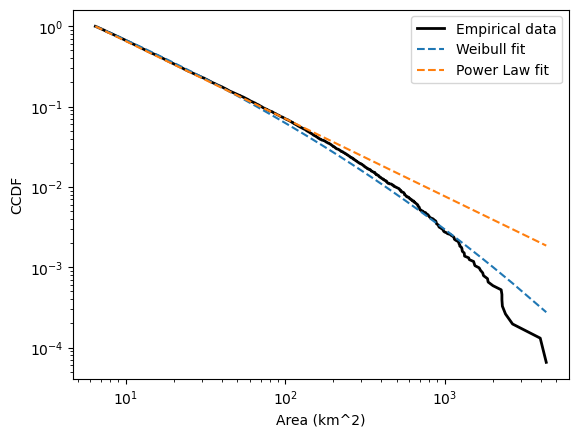

In [20]:
ax = wfpl.plot_ccdf_with_selected_fits(
    data, xmin=A["min_fire"], which=["weibull", "power_law"],
    save_figs=SAVE_FIGS
)

Verify that the fitting routine yields similar results when applied to the region in time and space where all 3 datasets overlap. The following code creates the overlapping spatial/temporal subsets.

In [21]:
mtbs_proj = dio.load_mtbs(P.mtbs / "S_USA.MTBS_BURN_AREA_BOUNDARY.shp", area_col="area_km2", region=MTBS_REGION)
idaho_gdf = dio.load_idaho(P.idaho / "HFD_HistoricFiresDatabase8_0.gdb")

mtbs_proj = dio.filter_years(mtbs_proj, "YEAR", A["modis_years"])
idaho_gdf = dio.filter_years(idaho_gdf, "FIRE_YEAR", A["modis_years"])

mtbs_overlap = dio.overlap_with(mtbs_proj, idaho_gdf, dedup_col="FIRE_ID")

gfa_combined_gdf = dio.load_gfa(P.gfa)
gfa_overlap = dio.overlap_with(gfa_combined_gdf, idaho_gdf, dedup_col="geometry")

Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2003.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2004.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2005.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2006.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2007.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimeter_2008.shp ...
Processing /Users/ambauer/Research/Projects/2026-1-Pres-Wildfires-BCKKS/wildfire_stats/data/gfa/data/Global_fire_atlas_V1_perimete

In [22]:
mtbs_data = mtbs_overlap["area_km2"].dropna().to_numpy()
gfa_data = gfa_overlap["area_km2"].dropna().to_numpy()
id_data = idaho_gdf["area_km2"].dropna().to_numpy()

MIN_FIRE = 4  # minimum fire size

R_QUICK = 10  # quick cross-dataset check (original used R=10, not static_R_boot)
mtbs_params = wfpl.summarize_parameters_bootstrap(mtbs_data, R=R_QUICK, 
                                                  xmin=MIN_FIRE, random_state=A["random_seed"])
gfa_params = wfpl.summarize_parameters_bootstrap(gfa_data, R=R_QUICK, 
                                                 xmin=MIN_FIRE, random_state=A["random_seed"])
id_params = wfpl.summarize_parameters_bootstrap(id_data, R=R_QUICK, 
                                                xmin=MIN_FIRE, random_state=A["random_seed"])

mtbs_R, mtbs_best = wfpl.likelihood_matrix_and_best(mtbs_data, xmin=MIN_FIRE)
gfa_R, gfa_best = wfpl.likelihood_matrix_and_best(gfa_data, xmin=MIN_FIRE)
id_R, id_best = wfpl.likelihood_matrix_and_best(id_data, xmin=MIN_FIRE)

mtbs_params, gfa_params, id_params

there are 4201 points above xmin 4.0 km^2
there are 3728 points above xmin 4.0 km^2
there are 4230 points above xmin 4.0 km^2


(                              p1     p1_se         p2     p2_se  reduces_to
 distribution                                                               
 exponential             0.023870  0.000793        NaN       NaN         NaN
 generalized_pareto      1.003309  0.028991   9.042029  0.317317         NaN
 lognormal               0.481099  0.258193   2.199481  0.085224         NaN
 lognormal_excess        2.217264  0.027015   1.749038  0.018856         NaN
 power_law               1.683201  0.007487        NaN       NaN         NaN
 stretched_exponential  10.801235  8.816966   0.221344  0.013849         NaN
 truncated_power_law     1.492905  0.019570   0.001708  0.000201         NaN
 weibull                 0.221344  0.013852   0.092586  0.061427         NaN
 weibull_excess          0.569914  0.007070  22.137405  0.537172         NaN,
                              p1     p1_se         p2     p2_se  reduces_to
 distribution                                                              


In [23]:
mtbs_R, gfa_R, id_R


(                       Δloglik vs stretched_exponential
 stretched_exponential                      0.000000e+00
 weibull                                    2.181514e-07
 lognormal                                  1.992000e+00
 truncated_power_law                        1.006911e+01
 generalized_pareto                         1.981477e+01
 power_law                                  1.280447e+02
 lognormal_excess                           1.476725e+02
 weibull_excess                             5.233608e+02
 exponential                                2.245328e+03,
                        Δloglik vs stretched_exponential
 stretched_exponential                      0.000000e+00
 weibull                                    2.488378e-08
 lognormal                                  1.288911e+00
 truncated_power_law                        1.676290e+01
 generalized_pareto                         1.832805e+01
 lognormal_excess                           1.363809e+02
 power_law                    

Close relative performance of different distributions on all 3 datasets!